# Quantum Receivers: Beating the Shot-Noise Limit

[`photons_in_semiconductors.ipynb`](photons_in_semiconductors.ipynb) ended at a
plateau. With a strong local oscillator, a coherent receiver becomes
*shot-noise limited*, which is the **standard quantum limit (SQL)** for receivers
that measure the field's amplitude. This notebook asks whether a receiver can do
better, and how.

**The task.** A laser pulse carries one bit as its phase: $|{+\alpha}\rangle$ or
$|{-\alpha}\rangle$ (BPSK), with mean photon number $N = \alpha^2$. Decide which
was sent with the smallest error probability.

| receiver | idea | error |
|---|---|---|
| homodyne (SQL) | measure one quadrature against a strong LO | $\tfrac12\operatorname{erfc}\sqrt{2N}$ |
| heterodyne | measure both quadratures | $\tfrac12\operatorname{erfc}\sqrt{N}$ |
| **Kennedy** | displace so that $+\alpha \to$ vacuum, then *count photons* | $\tfrac12 e^{-4N}$ |
| optimized Kennedy | displace slightly *past* $\alpha$ | minimize over $\beta$ (chain rule) |
| **Dolinar** | Kennedy with real-time feedback across the pulse | → Helstrom |
| **Helstrom bound** | the best *any* measurement can do | $\tfrac12\big(1 - \sqrt{1 - e^{-4N}}\big)$ |

Each closed form is checked by an independent route: Monte Carlo of the physical
measurement, or eigenvalues in a vector space. Module:
[`dgs/quantum_receivers.py`](../dgs/quantum_receivers.py).

In [1]:
import sys, pathlib
sys.path.insert(0, str(pathlib.Path.cwd().parent))

import numpy as np
import sympy as sp
import matplotlib.pyplot as plt
from scipy.optimize import brentq
from IPython.display import display, Math

from dgs.quantum_receivers import (
    homodyne_error, heterodyne_error, kennedy_error, displaced_counting_error,
    optimized_kennedy, optimized_kennedy_condition, overlap, helstrom_error,
    kennedy_helstrom_ratio_limit, coherent_state, helstrom_error_fock,
    helstrom_measurement_check, mc_homodyne, mc_heterodyne, mc_displaced_counting,
    displaced_counting_error_imperfect, dolinar_error, mc_dolinar,
    squeezed_homodyne_error, optimal_squeezing,
)

# 1. Why errors are unavoidable: non-orthogonal vectors

A coherent state is a vector in the infinite-dimensional Fock space:

$$|\alpha\rangle = e^{-|\alpha|^2/2}\sum_{n=0}^\infty \frac{\alpha^n}{\sqrt{n!}}\,|n\rangle$$

The two signals aren't orthogonal. Their inner product is
$\langle\alpha|{-\alpha}\rangle = e^{-2N} \ne 0$. No measurement can perfectly
separate non-orthogonal vectors. The minimum possible error is the **Helstrom
bound**, which comes from linear algebra:

$$P_H = \tfrac12\Big(1 - \big\|\tfrac12\rho_+ - \tfrac12\rho_-\big\|_1\Big),\qquad \|A\|_1 = \sum_i|\lambda_i(A)|$$

The optimal measurement projects onto the eigenvectors of $\rho_+ - \rho_-$ that
have positive eigenvalues. Below, both the bound and the error of that projector
are computed by eigen-decomposition in a 60-dimensional truncated Fock space and
compared with the closed form.

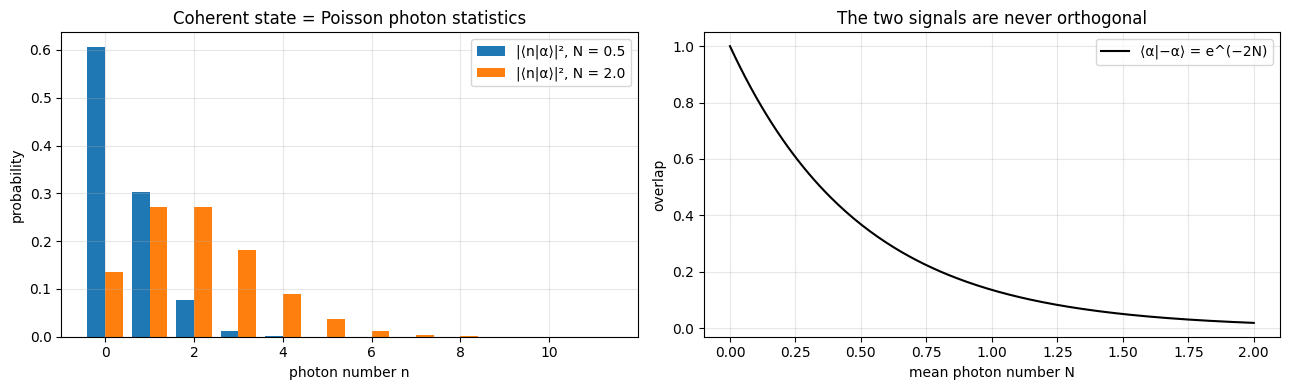

    N  Helstrom closed form  eigenvalues (Fock)  optimal projector
  0.1          2.129112e-01        2.129112e-01       2.129112e-01
  0.5          3.506325e-02        3.506325e-02       3.506325e-02
  1.0          4.600070e-03        4.600070e-03       4.600070e-03
  2.0          8.387269e-05        8.387269e-05       8.387269e-05
  4.0          2.813379e-08        2.813379e-08       2.813379e-08


In [2]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
n = np.arange(12)
for N, col in ((0.5, "C0"), (2.0, "C1")):
    a = np.sqrt(N)
    axes[0].bar(n + (0.2 if N > 1 else -0.2), np.abs(coherent_state(a, 12))**2, 0.4, color=col, label=f"|⟨n|α⟩|², N = {N}")
axes[0].set(xlabel="photon number n", ylabel="probability", title="Coherent state = Poisson photon statistics")
axes[0].legend(); axes[0].grid(alpha=0.3)
Ns = np.linspace(0, 2, 200)
axes[1].plot(Ns, overlap(Ns), "k", label="⟨α|−α⟩ = e^(−2N)")
axes[1].set(xlabel="mean photon number N", ylabel="overlap", title="The two signals are never orthogonal")
axes[1].legend(); axes[1].grid(alpha=0.3)
plt.tight_layout(); plt.show()

print(f"{'N':>5s} {'Helstrom closed form':>21s} {'eigenvalues (Fock)':>19s} {'optimal projector':>18s}")
for N in (0.1, 0.5, 1.0, 2.0, 4.0):
    err, closed = helstrom_measurement_check(N)
    print(f"{N:5.1f} {closed:21.6e} {helstrom_error_fock(N):19.6e} {err:18.6e}")

# 2. Classical receivers: homodyne and heterodyne

Homodyne measures $\hat x = \hat a + \hat a^\dagger$. For $|{\pm\alpha}\rangle$ the
outcome is Gaussian with mean $\pm2\alpha$ and **vacuum variance 1**. That vacuum
noise is the shot noise. Deciding by the sign gives an error equal to a Gaussian
tail integral:

$$P_\text{hom} = \int_{2\alpha}^\infty \frac{e^{-x^2/2}}{\sqrt{2\pi}}dx = \tfrac12\operatorname{erfc}\sqrt{2N}$$

Heterodyne measures both quadratures at once and pays one extra unit of vacuum
noise, so its error is $\tfrac12\operatorname{erfc}\sqrt{N}$.

In [3]:
print(f"{'N':>5s} {'homodyne':>10s} {'MC':>10s} {'heterodyne':>11s} {'MC':>10s}")
for N in (0.2, 0.5, 1.0, 2.0):
    print(f"{N:5.1f} {homodyne_error(N):10.5f} {mc_homodyne(N, 400_000, seed=1):10.5f} "
          f"{heterodyne_error(N):11.5f} {mc_heterodyne(N, 400_000, seed=2):10.5f}")

    N   homodyne         MC  heterodyne         MC
  0.2    0.18555    0.18499     0.26354    0.26295
  0.5    0.07865    0.07814     0.15866    0.15807
  1.0    0.02275    0.02304     0.07865    0.07862
  2.0    0.00234    0.00239     0.02275    0.02270


# 3. The Kennedy receiver: turn phase into "click or no click"

Add a displacement $-\alpha$ by interfering with a weak, phase-locked LO on a
high-transmission beam splitter:

$$|{+\alpha}\rangle \to |0\rangle\ (\text{vacuum}),\qquad |{-\alpha}\rangle \to |{-2\alpha}\rangle$$

Then use a photon counter. Vacuum *never* clicks. So "no click" means $+$, and
"any click" means $-$. The only error is $|{-2\alpha}\rangle$ happening to produce
zero photons, which has Poisson probability $e^{-4N}$:

$$P_K = \tfrac12 e^{-4N}$$

Homodyne errors decay as $e^{-2N}$ (an erfc tail), while Kennedy errors decay as
$e^{-4N}$, which is twice as fast in the exponent.

In [4]:
N_cross = brentq(lambda N: kennedy_error(N) - homodyne_error(N), 0.05, 2)
print(f"Kennedy beats homodyne for N > {N_cross:.3f} photons")
for N in (0.2, 1.0, 2.0):
    print(f"N = {N}: Kennedy {kennedy_error(N):.5f}   Monte Carlo (Poisson clicks) {mc_displaced_counting(N, np.sqrt(N), 400_000, seed=3):.5f}")
lim = kennedy_helstrom_ratio_limit()
print(f"\nSymPy:  lim_(N→∞) P_Kennedy / P_Helstrom = {lim}")

Kennedy beats homodyne for N > 0.384 photons
N = 0.2: Kennedy 0.22466   Monte Carlo (Poisson clicks) 0.22429
N = 1.0: Kennedy 0.00916   Monte Carlo (Poisson clicks) 0.00922


N = 2.0: Kennedy 0.00017   Monte Carlo (Poisson clicks) 0.00020



SymPy:  lim_(N→∞) P_Kennedy / P_Helstrom = 2


**A squeeze-theorem view.** For every $N$, every receiver satisfies
$P_H \le P \le \tfrac12$. Kennedy is *exponentially* optimal: the ratio
$P_K/P_H \to 2$, a constant, as $N\to\infty$. SymPy evaluates that limit. Both
errors go to zero at the same exponential rate. The fixed factor of 2 is all that
feedback (Part 5) still has to recover.

# 4. Optimized Kennedy: the chain rule finds a better displacement

Displace by $-\beta$ instead of $-\alpha$:

$$P(\beta) = \tfrac12\Big[\underbrace{1 - e^{-(\alpha-\beta)^2}}_{+\text{ clicks}} + \underbrace{e^{-(\alpha+\beta)^2}}_{-\text{ silent}}\Big]$$

Setting $dP/d\beta = 0$ (chain rule on each exponent) gives the optimum condition:

<IPython.core.display.Math object>

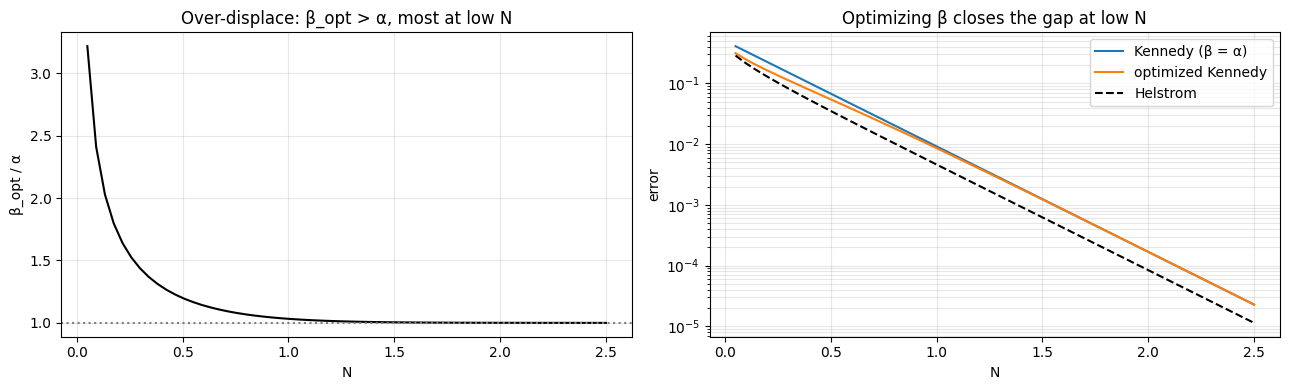

In [5]:
display(Math(r"\frac{dP}{d\beta} = " + sp.latex(optimized_kennedy_condition())))
Ns = np.linspace(0.05, 2.5, 60)
opt = np.array([optimized_kennedy(N) for N in Ns])
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
axes[0].plot(Ns, opt[:, 0]/np.sqrt(Ns), "k")
axes[0].axhline(1, color="0.5", ls=":")
axes[0].set(xlabel="N", ylabel="β_opt / α", title="Over-displace: β_opt > α, most at low N")
axes[0].grid(alpha=0.3)
axes[1].semilogy(Ns, kennedy_error(Ns), label="Kennedy (β = α)")
axes[1].semilogy(Ns, opt[:, 1], label="optimized Kennedy")
axes[1].semilogy(Ns, helstrom_error(Ns), "k--", label="Helstrom")
axes[1].set(xlabel="N", ylabel="error", title="Optimizing β closes the gap at low N"); axes[1].legend(); axes[1].grid(alpha=0.3, which="both")
plt.tight_layout(); plt.show()

# 5. Dolinar-type feedback: reaching the Helstrom bound

Split the pulse in time into $M$ slices, each the coherent state $|{\pm\alpha/\sqrt M}\rangle$.
Before each slice:

1. Pick the displacement that best separates the two hypotheses given the current
   belief $p = P(+\,|\,\text{clicks so far})$.
2. Record click or no click, and update $p$ with **Bayes' rule**.

At the end, decide whichever hypothesis is more likely. With $M = 1$ this *is* the
optimized Kennedy receiver. As $M\to\infty$ it approaches the Helstrom bound
(Dolinar 1973; this per-slice greedy form follows Assalini, Dalla Pozza & Pierobon,
2011). The error below is computed **exactly** by recursing over all $2^M$ click
histories, and checked by Monte Carlo.

N = 0.5: M=1 0.05436 (= optimized Kennedy 0.05436),  M=12 0.03788,  1/M→0 extrapolation 0.03571,  Helstrom 0.03506


N = 1.0: M=1 0.00856 (= optimized Kennedy 0.00856),  M=12 0.00524,  1/M→0 extrapolation 0.00475,  Helstrom 0.00460


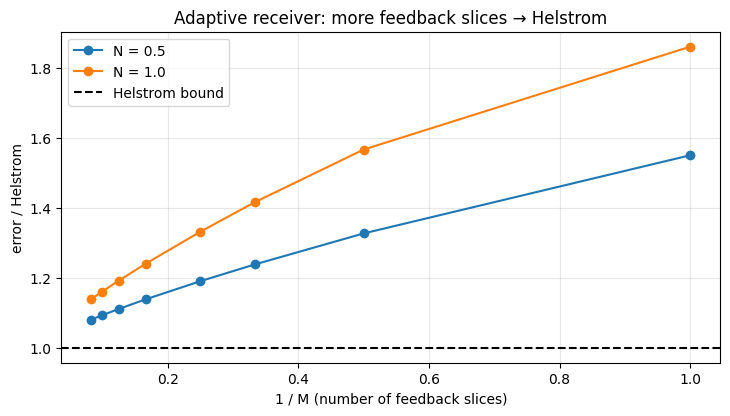


Monte Carlo check, N = 1, M = 8: exact 0.00548,  MC (100k pulses) 0.00589


In [6]:
Ms = [1, 2, 3, 4, 6, 8, 10, 12]
fig, ax = plt.subplots(figsize=(8.5, 4.3))
for N, col in ((0.5, "C0"), (1.0, "C1")):
    e = np.array([dolinar_error(N, M) for M in Ms])
    H = helstrom_error(N)
    ax.plot(1/np.array(Ms), e/H, "o-", color=col, label=f"N = {N}")
    slope = (e[-2] - e[-1])/(1/Ms[-2] - 1/Ms[-1])
    ext = e[-1] - slope/Ms[-1]
    print(f"N = {N}: M=1 {e[0]:.5f} (= optimized Kennedy {optimized_kennedy(N)[1]:.5f}),  M=12 {e[-1]:.5f},  "
          f"1/M→0 extrapolation {ext:.5f},  Helstrom {H:.5f}")
ax.axhline(1, color="k", ls="--", label="Helstrom bound")
ax.set(xlabel="1 / M (number of feedback slices)", ylabel="error / Helstrom",
       title="Adaptive receiver: more feedback slices → Helstrom")
ax.legend(); ax.grid(alpha=0.3); plt.show()
print(f"\nMonte Carlo check, N = 1, M = 8: exact {dolinar_error(1.0, 8):.5f},  MC (100k pulses) {mc_dolinar(1.0, 8, trials=100_000, seed=6):.5f}")

# 6. Real detectors: efficiency and dark counts

Kennedy-type receivers depend on "vacuum never clicks." A **dark count** breaks
that, and losses (efficiency $\eta < 1$) shrink the signal. Homodyne detectors
routinely reach about 99% efficiency. Single-photon counters with near-unity
efficiency (superconducting nanowires) are a big reason these receivers became
practical.

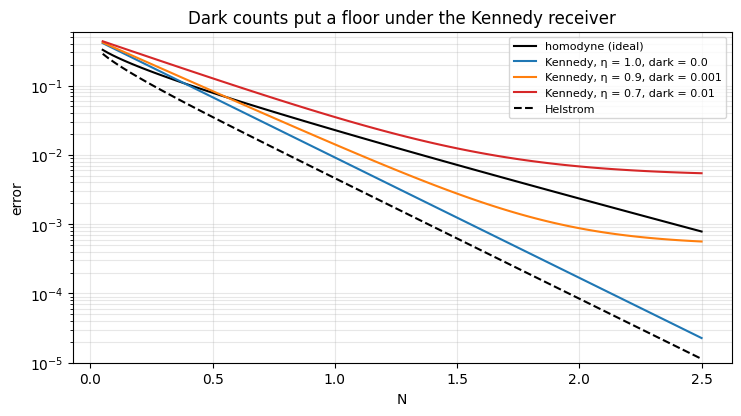

N = 1, η = 0.9, dark = 1e-3:  closed form 0.01415,  MC 0.01386


In [7]:
Ns = np.linspace(0.05, 2.5, 120)
fig, ax = plt.subplots(figsize=(8.5, 4.3))
ax.semilogy(Ns, homodyne_error(Ns), "k", label="homodyne (ideal)")
for eta, dark, col in ((1.0, 0.0, "C0"), (0.9, 1e-3, "C1"), (0.7, 1e-2, "C3")):
    ax.semilogy(Ns, displaced_counting_error_imperfect(Ns, np.sqrt(Ns), eta, dark), color=col,
                label=f"Kennedy, η = {eta}, dark = {dark}")
ax.semilogy(Ns, helstrom_error(Ns), "k--", label="Helstrom")
ax.set(xlabel="N", ylabel="error", ylim=(1e-5, 0.6), title="Dark counts put a floor under the Kennedy receiver")
ax.legend(fontsize=8); ax.grid(alpha=0.3, which="both"); plt.show()
N, b = 1.0, 1.0
print(f"N = 1, η = 0.9, dark = 1e-3:  closed form {displaced_counting_error_imperfect(N, b, 0.9, 1e-3):.5f},  "
      f"MC {mc_displaced_counting(N, b, 400_000, dark=1e-3, eta=0.9, seed=7):.5f}")

# 7. Squeezing: change the states, not the receiver

Keep homodyne detection, but send **squeezed** coherent states. The noise in
$\hat x$ is reduced by $e^{-2r}$ (and increased in $\hat p$). Squeezing itself costs
photons, so at a fixed energy budget

$$N = \alpha^2 + \sinh^2 r,\qquad P = \tfrac12\operatorname{erfc}\!\big(\sqrt2\,\alpha e^{r}\big)$$

and there's an optimal amount of squeezing. Maximizing
$(N - \sinh^2 r)\,e^{2r}$ is a one-variable calculus problem (SymPy derivative,
numerical root).

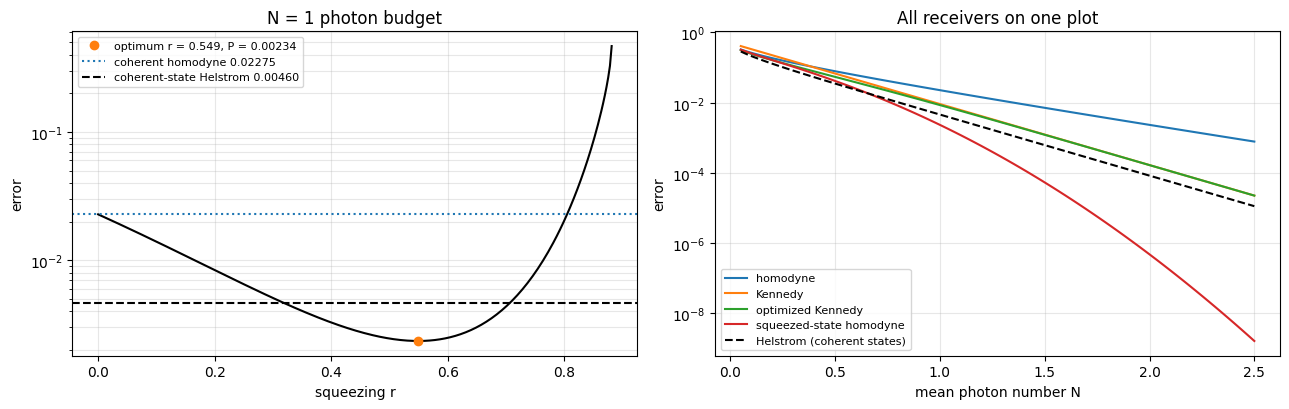

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.2))
N = 1.0
rs = np.linspace(0, np.arcsinh(np.sqrt(N)) - 1e-4, 300)
axes[0].semilogy(rs, [squeezed_homodyne_error(N, r) for r in rs], "k")
r_opt, P_opt = optimal_squeezing(N)
axes[0].plot(r_opt, P_opt, "o", color="C1", label=f"optimum r = {r_opt:.3f}, P = {P_opt:.5f}")
axes[0].axhline(homodyne_error(N), color="C0", ls=":", label=f"coherent homodyne {homodyne_error(N):.5f}")
axes[0].axhline(helstrom_error(N), color="k", ls="--", label=f"coherent-state Helstrom {helstrom_error(N):.5f}")
axes[0].set(xlabel="squeezing r", ylabel="error", title="N = 1 photon budget"); axes[0].legend(fontsize=8); axes[0].grid(alpha=0.3, which="both")

Ns = np.linspace(0.05, 2.5, 80)
axes[1].semilogy(Ns, homodyne_error(Ns), label="homodyne")
axes[1].semilogy(Ns, kennedy_error(Ns), label="Kennedy")
axes[1].semilogy(Ns, [optimized_kennedy(x)[1] for x in Ns], label="optimized Kennedy")
axes[1].semilogy(Ns, [optimal_squeezing(x)[1] for x in Ns], label="squeezed-state homodyne")
axes[1].semilogy(Ns, helstrom_error(Ns), "k--", label="Helstrom (coherent states)")
axes[1].set(xlabel="mean photon number N", ylabel="error", title="All receivers on one plot")
axes[1].legend(fontsize=8); axes[1].grid(alpha=0.3, which="both")
plt.tight_layout(); plt.show()

**Squeezed homodyne beats the coherent-state Helstrom bound. Is that a
contradiction?** No. The Helstrom bound is a limit on *measurements* for a *given
pair of states*. Squeezing changes the states, so it's a different alphabet with
its own, lower Helstrom bound. Both routes are used in practice: better
measurements (Kennedy and Dolinar receivers have been demonstrated experimentally),
and better states (squeezed light injected into LIGO's detectors).

# Summary

| result | checked by |
|---|---|
| homodyne $\tfrac12\operatorname{erfc}\sqrt{2N}$, heterodyne $\tfrac12\operatorname{erfc}\sqrt{N}$ | Monte Carlo Gaussian quadratures |
| Kennedy $\tfrac12 e^{-4N}$, beats homodyne above a crossover N | Monte Carlo Poisson clicks |
| $P_K/P_H \to 2$ | SymPy limit |
| optimized Kennedy over-displaces | SymPy derivative + numerical minimum |
| Helstrom bound and its optimal projector | eigenvalues in a 60-dim Fock space |
| adaptive (Dolinar-type) receiver → Helstrom as $M$ grows | exact $2^M$-history recursion + Monte Carlo |
| squeezing helps homodyne at fixed energy | SymPy derivative + scan |

**Math used:** vector spaces and eigenvalues (Helstrom), Gaussian tail integrals
(homodyne), limits (the Kennedy/Helstrom ratio), the chain rule (optimized
Kennedy, squeezing), and Bayes' rule (Dolinar).

**Open source.** Tools like QuTiP, Strawberry Fields (photonic, continuous-variable)
and Qiskit let anyone reproduce results like these and check them independently.
That's the same standard every number in this notebook was held to.

## Exercises
1. Extend to QPSK (four phases $\alpha, i\alpha, -\alpha, -i\alpha$). The Helstrom bound now needs the "square-root measurement" or an SDP. What's homodyne's analog?
2. Add dark counts to `dolinar_error`. Does feedback still help?
3. Optimize the displacement *phase* as well as its magnitude. Does it help for real-valued $\alpha$?
4. Prove $\langle\alpha|\beta\rangle = e^{-|\alpha|^2/2 - |\beta|^2/2 + \alpha^*\beta}$ from the Fock expansion.
5. At what $N$ does a 1% error rate need 3 dB less energy with Kennedy than with homodyne?